In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv(r"C:\Users\24108244\Desktop\blood_transfusion.csv")

In [6]:
df.head()

,Recency,Frequency,Monetary,Time,Donated_Blood
0,2,50,12500,98,1
1,0,13,3250,28,1
2,1,16,4000,35,1
3,2,20,5000,45,1
4,1,24,6000,77,0


In [7]:
df.shape

(748, 5)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Recency        748 non-null    int64
 1   Frequency      748 non-null    int64
 2   Monetary       748 non-null    int64
 3   Time           748 non-null    int64
 4   Donated_Blood  748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB


In [9]:
df.describe()

,Recency,Frequency,Monetary,Time,Donated_Blood
count,748.000000,748.000000,748.000000,748.000000,748.000000
mean,9.506684,5.514706,1378.676471,34.282086,0.237968
std,8.095396,5.839307,1459.826781,24.376714,0.426124
min,0.000000,1.000000,250.000000,2.000000,0.000000
25%,2.750000,2.000000,500.000000,16.000000,0.000000
50%,7.000000,4.000000,1000.000000,28.000000,0.000000
75%,14.000000,7.000000,1750.000000,50.000000,0.000000
max,74.000000,50.000000,12500.000000,98.000000,1.000000


In [10]:
df.isnull().sum()

Recency          0
Frequency        0
Monetary         0
Time             0
Donated_Blood    0
dtype: int64

In [11]:
int(df.duplicated().sum())

215

In [12]:
df['Donated_Blood'].value_counts()

0    570
1    178
Name: Donated_Blood, dtype: int64

In [13]:
df.corr()

,Recency,Frequency,Monetary,Time,Donated_Blood
Recency,1.000000,-0.182745,-0.182745,0.160618,-0.279869
Frequency,-0.182745,1.000000,1.000000,0.634940,0.218633
Monetary,-0.182745,1.000000,1.000000,0.634940,0.218633
Time,0.160618,0.634940,0.634940,1.000000,-0.035854
Donated_Blood,-0.279869,0.218633,0.218633,-0.035854,1.000000


In [14]:
df = df.drop('Monetary', axis=1)

In [15]:
df.head()

,Recency,Frequency,Time,Donated_Blood
0,2,50,98,1
1,0,13,28,1
2,1,16,35,1
3,2,20,45,1
4,1,24,77,0


In [16]:
X = df.drop('Donated_Blood', axis=1).values

In [17]:
y = df['Donated_Blood'].values

In [18]:
np.random.seed(42)

In [19]:
idx = np.random.permutation(len(X))

In [20]:
X = X[idx]
y = y[idx]

In [21]:
split = int(0.8 * len(X))

In [22]:
X_train = X[:split]
X_test = X[split:]

In [23]:
y_train = y[:split]
y_test = y[split:]

In [24]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

In [25]:
X_train = (X_train - mean) / std

In [26]:
X_test = (X_test - mean) / std

In [27]:
print(X_train.shape, X_test.shape)

(598, 3) (150, 3)


In [28]:
weights = np.zeros(X_train.shape[1])
bias = 0

In [29]:
learning_rate = 0.01
epochs = 100

In [30]:
def predict(X, weights, bias):
    z = np.dot(X, weights) + bias
    return np.where(z >= 0, 1, 0)

In [31]:
errors = []
for epoch in range(epochs):
    wrong = 0
    for xi, target in zip(X_train, y_train):
        pred = predict(xi, weights, bias)
        update = learning_rate * (target - pred)
        weights = weights + update * xi
        bias = bias + update
        wrong += int(update != 0)
    errors.append(wrong)

In [32]:
print(weights)
print(bias)

[-0.00993271  0.0207848  -0.02446885]
-0.03


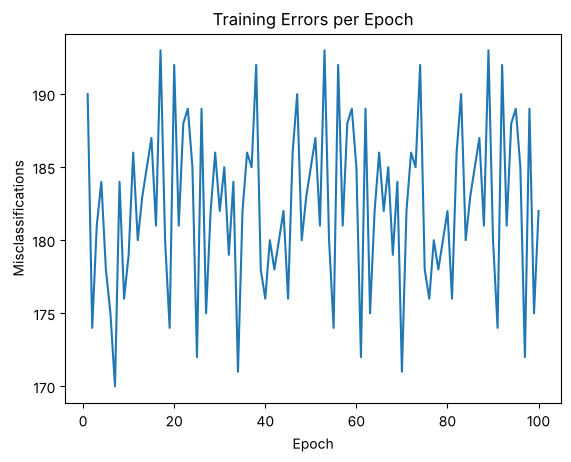

In [32]:
plt.plot(range(1, epochs + 1), errors)
plt.xlabel('Epoch')
plt.ylabel('Misclassifications')
plt.title('Training Errors per Epoch')
plt.show()

In [33]:
y_pred = predict(X_test, weights, bias)

In [34]:
TP = int(np.sum((y_test == 1) & (y_pred == 1)))
TN = int(np.sum((y_test == 0) & (y_pred == 0)))
FP = int(np.sum((y_test == 0) & (y_pred == 1)))
FN = int(np.sum((y_test == 1) & (y_pred == 0)))

In [35]:
print([[TN, FP], [FN, TP]])

[[116, 2], [25, 7]]


In [36]:
accuracy = (TP + TN) / (TP + TN + FP + FN)

In [37]:
precision = TP / (TP + FP) if (TP + FP) > 0 else 0

In [38]:
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

In [39]:
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

In [40]:
print('Accuracy :', round(accuracy, 4))
print('Precision:', round(precision, 4))
print('Recall   :', round(recall, 4))
print('F1 Score :', round(f1, 4))

Accuracy : 0.82
Precision: 0.7778
Recall   : 0.2188
F1 Score : 0.3415


In [41]:
train_pred = predict(X_train, weights, bias)
print('Train Accuracy:', round(np.mean(train_pred == y_train), 4))
print('Test Accuracy :', round(np.mean(y_pred == y_test), 4))

Train Accuracy: 0.7625
Test Accuracy : 0.82


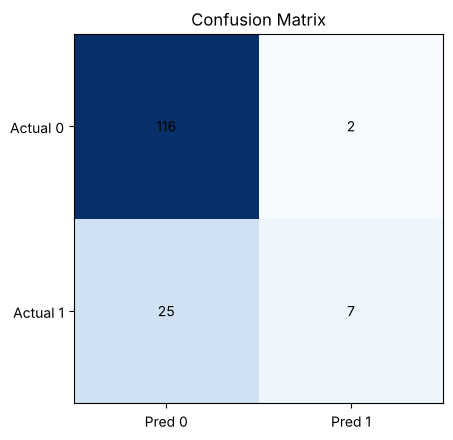

In [42]:
plt.imshow([[TN, FP], [FN, TP]], cmap='Blues')
plt.xticks([0, 1], ['Pred 0', 'Pred 1'])
plt.yticks([0, 1], ['Actual 0', 'Actual 1'])
for i, row in enumerate([[TN, FP], [FN, TP]]):
    for j, v in enumerate(row):
        plt.text(j, i, v, ha='center', va='center')
plt.title('Confusion Matrix')
plt.show()